# Project 2: Housing Price Prediction – Pass 09

## Problem Definition


State the business problem. Translate the business problem into a Data Science problem by stating what kind of problem it is ( supervised vs unsupervised ) and whether it is a classification, regression, or clustering problem.

Statement:

We want to predict housing sale prices based on various correlated feature data. This is a *supervised regression* problem, where the target of the prediction is sales prices. To accomplish this, we use a regression model alongside Regression prediction techniques, as well as feature scaling and regularization to minimize the RMS percentage error.

## Data Collection/Sources


Data Collection describes the process by which we obtain the data for use in the project. In this case, our data comes from S3 storage buckets on AWS, which we load into memory (variables) via URLs by passing them to the read_csv function of the pandas python library (more on that soon).

The data comes in one large set containing the full data available for use in the project. It is supplemented by a data dictionary that describes the set, the data types of the included data, and other information relevant to its use.

Finally, to store the data in a form we can work with in memory, we use a storage structure called a DataFrame object from the pandas python library. This object allows us to quickly view the data and preview operations on the data without changing it, as well as make updates to the data in a highly intuitive way.

First, load Pandas, Numpy, and Matplotlib modules:

In [319]:
# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm

from sklearn import datasets, metrics, model_selection
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score

from sklearn.preprocessing import StandardScaler

Load data Train.csv from AWS S3:

In [237]:
# url
url = 'https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv'

Next, make a preview DataFrame to look at columns:

In [238]:
# make preview
df_preview = pd.read_csv(url, nrows=1)
df_preview

,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,905101070,20,RL,62.0,14299,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,7,2007,WD,Normal,115400


In [239]:
# preview all column names
df_preview.columns

Index(['PID', 'MS SubClass', 'MS Zoning', 'Lot Frontage', 'Lot Area', 'Street',
       'Alley', 'Lot Shape', 'Land Contour', 'Utilities', 'Lot Config',
       'Land Slope', 'Neighborhood', 'Condition 1', 'Condition 2', 'Bldg Type',
       'House Style', 'Overall Qual', 'Overall Cond', 'Year Built',
       'Year Remod/Add', 'Roof Style', 'Roof Matl', 'Exterior 1st',
       'Exterior 2nd', 'Mas Vnr Type', 'Mas Vnr Area', 'Exter Qual',
       'Exter Cond', 'Foundation', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure',
       'BsmtFin Type 1', 'BsmtFin SF 1', 'BsmtFin Type 2', 'BsmtFin SF 2',
       'Bsmt Unf SF', 'Total Bsmt SF', 'Heating', 'Heating QC', 'Central Air',
       'Electrical', '1st Flr SF', '2nd Flr SF', 'Low Qual Fin SF',
       'Gr Liv Area', 'Bsmt Full Bath', 'Bsmt Half Bath', 'Full Bath',
       'Half Bath', 'Bedroom AbvGr', 'Kitchen AbvGr', 'Kitchen Qual',
       'TotRms AbvGrd', 'Functional', 'Fireplaces', 'Fireplace Qu',
       'Garage Type', 'Garage Yr Blt', 'Garage Finish'

Define the target column (and features types, if required):

In [240]:
# define target column (by name) and target features type
target_col = "SalePrice"
feature_types = ["float64"]

Create list of target col and feature cols:

In [241]:
# use list comprehension to generate list of target col + selected feature cols
selected_cols = [
    col
    for col in df_preview.columns
    if col == target_col or df_preview[col].dtype in feature_types
]
selected_cols

['Lot Frontage',
 'Alley',
 'Mas Vnr Type',
 'Mas Vnr Area',
 'BsmtFin SF 1',
 'BsmtFin SF 2',
 'Bsmt Unf SF',
 'Total Bsmt SF',
 'Bsmt Full Bath',
 'Bsmt Half Bath',
 'Fireplace Qu',
 'Garage Yr Blt',
 'Garage Cars',
 'Garage Area',
 'Pool QC',
 'Misc Feature',
 'SalePrice']

Read in the data from .csv using target_col and feature_types:

In [242]:
# make dataframe
df = pd.read_csv( url, usecols=selected_cols )

Finally, check the dataframe:

In [243]:
# check dataframe
df

,Lot Frontage,Alley,Mas Vnr Type,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Bsmt Full Bath,Bsmt Half Bath,Fireplace Qu,Garage Yr Blt,Garage Cars,Garage Area,Pool QC,Misc Feature,SalePrice
0,62.0,NaN,NaN,0.0,513.0,144.0,348.0,1005.0,1.0,0.0,NaN,1964.0,2.0,440.0,NaN,NaN,115400
1,72.0,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,1967.0,2.0,516.0,NaN,Shed,90000
2,50.0,NaN,NaN,0.0,0.0,0.0,780.0,780.0,0.0,0.0,Gd,1979.0,1.0,544.0,NaN,NaN,141000
3,68.0,NaN,NaN,0.0,484.0,0.0,491.0,975.0,1.0,0.0,TA,2000.0,2.0,592.0,NaN,NaN,254000
4,60.0,NaN,NaN,0.0,350.0,210.0,0.0,560.0,1.0,0.0,NaN,1971.0,2.0,576.0,NaN,NaN,155000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,52.0,NaN,NaN,0.0,0.0,0.0,816.0,816.0,0.0,0.0,Gd,1985.0,2.0,528.0,NaN,Shed,114500
2633,74.0,NaN,NaN,0.0,460.0,286.0,308.0,1054.0,1.0,0.0,NaN,1990.0,2.0,462.0,NaN,NaN,162000
2634,61.0,NaN,NaN,0.0,960.0,0.0,266.0,1226.0,1.0,0.0,TA,1981.0,2.0,484.0,NaN,NaN,211500
2635,78.0,NaN,BrkFace,174.0,0.0,0.0,1064.0,1064.0,0.0,0.0,TA,1974.0,2.0,478.0,NaN,NaN,165000


## Data Cleaning


Data Cleaning is the process of preparing the data set for use in analysis. Many data sets contain bad or null (empty) values, which can cause errors when trying to work with the data and use it in code. Cleaning the data involves removing bad (null-containing) columns and/or rows from the set, as well as imputing (replacing via insertion) similar data into fields with missing or unusable values.

Here, to clean the data, we mostly use the pandas drop function included with pandas DataFrame objects, which allow us to drop columns and rows according to conditions we specify, much like SQL WHERE clauses.

#### 4. Examine the data using tools we have used in class. You should be identifying the various columns such as ...

    - target column
    - feature columns
    - identifier columns
    - null columns
    - null rows

    Tools you should be using include, but are not limited to:

    - head
    - tail
    - shape
    - size
    - info
    - describe
    - nunique
    - unique
    - isnull/isna



- head

In [244]:
# head
df.head()

,Lot Frontage,Alley,Mas Vnr Type,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Bsmt Full Bath,Bsmt Half Bath,Fireplace Qu,Garage Yr Blt,Garage Cars,Garage Area,Pool QC,Misc Feature,SalePrice
0,62.0,NaN,NaN,0.0,513.0,144.0,348.0,1005.0,1.0,0.0,NaN,1964.0,2.0,440.0,NaN,NaN,115400
1,72.0,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,1967.0,2.0,516.0,NaN,Shed,90000
2,50.0,NaN,NaN,0.0,0.0,0.0,780.0,780.0,0.0,0.0,Gd,1979.0,1.0,544.0,NaN,NaN,141000
3,68.0,NaN,NaN,0.0,484.0,0.0,491.0,975.0,1.0,0.0,TA,2000.0,2.0,592.0,NaN,NaN,254000
4,60.0,NaN,NaN,0.0,350.0,210.0,0.0,560.0,1.0,0.0,NaN,1971.0,2.0,576.0,NaN,NaN,155000


- tail

In [245]:
# tail
df.tail()

,Lot Frontage,Alley,Mas Vnr Type,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Bsmt Full Bath,Bsmt Half Bath,Fireplace Qu,Garage Yr Blt,Garage Cars,Garage Area,Pool QC,Misc Feature,SalePrice
2632,52.0,NaN,NaN,0.0,0.0,0.0,816.0,816.0,0.0,0.0,Gd,1985.0,2.0,528.0,NaN,Shed,114500
2633,74.0,NaN,NaN,0.0,460.0,286.0,308.0,1054.0,1.0,0.0,NaN,1990.0,2.0,462.0,NaN,NaN,162000
2634,61.0,NaN,NaN,0.0,960.0,0.0,266.0,1226.0,1.0,0.0,TA,1981.0,2.0,484.0,NaN,NaN,211500
2635,78.0,NaN,BrkFace,174.0,0.0,0.0,1064.0,1064.0,0.0,0.0,TA,1974.0,2.0,478.0,NaN,NaN,165000
2636,41.0,NaN,NaN,0.0,870.0,0.0,167.0,1037.0,0.0,0.0,TA,1999.0,2.0,400.0,NaN,NaN,225000


- shape

In [246]:
# shape
df.shape

(2637, 17)

- size

In [247]:
# size
df.size

44829

- info

In [248]:
# info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2637 entries, 0 to 2636
Data columns (total 17 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Lot Frontage    2188 non-null   float64
 1   Alley           180 non-null    object 
 2   Mas Vnr Type    1030 non-null   object 
 3   Mas Vnr Area    2614 non-null   float64
 4   BsmtFin SF 1    2636 non-null   float64
 5   BsmtFin SF 2    2636 non-null   float64
 6   Bsmt Unf SF     2636 non-null   float64
 7   Total Bsmt SF   2636 non-null   float64
 8   Bsmt Full Bath  2635 non-null   float64
 9   Bsmt Half Bath  2635 non-null   float64
 10  Fireplace Qu    1353 non-null   object 
 11  Garage Yr Blt   2490 non-null   float64
 12  Garage Cars     2636 non-null   float64
 13  Garage Area     2636 non-null   float64
 14  Pool QC         11 non-null     object 
 15  Misc Feature    96 non-null     object 
 16  SalePrice       2637 non-null   int64  
dtypes: float64(11), int64(1), object(

- describe

In [249]:
# describe
df.describe()

,Lot Frontage,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Bsmt Full Bath,Bsmt Half Bath,Garage Yr Blt,Garage Cars,Garage Area,SalePrice
count,2188.000000,2614.000000,2636.000000,2636.000000,2636.000000,2636.000000,2635.000000,2635.000000,2490.000000,2636.000000,2636.000000,2637.000000
mean,69.166819,101.887911,438.441199,51.068665,555.669196,1045.179059,0.432258,0.058824,1978.185944,1.763278,470.968134,179986.230186
std,23.356779,179.578232,449.602326,172.521803,436.223188,429.686089,0.525239,0.240130,25.452647,0.760576,212.816905,78309.251522
min,21.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1895.000000,0.000000,0.000000,12789.000000
25%,58.000000,0.000000,0.000000,0.000000,218.000000,792.000000,0.000000,0.000000,1961.000000,1.000000,324.750000,129500.000000
50%,68.000000,0.000000,368.000000,0.000000,464.500000,988.000000,0.000000,0.000000,1979.000000,2.000000,480.000000,160000.000000
75%,80.000000,164.000000,732.000000,0.000000,797.250000,1290.250000,1.000000,0.000000,2002.000000,2.000000,576.000000,213000.000000
max,313.000000,1600.000000,5644.000000,1526.000000,2336.000000,6110.000000,3.000000,2.000000,2207.000000,5.000000,1488.000000,745000.000000


- nunique

In [250]:
# nunique
df.nunique().sort_values( ascending = False )

,0
Bsmt Unf SF,1080
Total Bsmt SF,1001
SalePrice,983
BsmtFin SF 1,935
Garage Area,576
Mas Vnr Area,425
BsmtFin SF 2,253
Lot Frontage,126
Garage Yr Blt,102
Garage Cars,6


In [251]:
# normalize to look for ID column(s)
df.nunique().sort_values( ascending = False ) / df.shape[0] * 100

,0
Bsmt Unf SF,40.955631
Total Bsmt SF,37.959803
SalePrice,37.277209
BsmtFin SF 1,35.456959
Garage Area,21.843003
Mas Vnr Area,16.116799
BsmtFin SF 2,9.594236
Lot Frontage,4.778157
Garage Yr Blt,3.868032
Garage Cars,0.227531


- unique

In [252]:
# unique
df[target_col].unique()

array([115400,  90000, 141000, 254000, 155000, 125000, 194500, 185000,
       235000, 152000, 201000, 207000, 192000, 174000, 190000, 176000,
       384500, 395039, 167000, 165000, 195000, 104500, 161000, 245700,
       226001, 153500, 139000,  35000, 181000, 212000, 156000, 139500,
       225000,  12789, 157500, 110000, 130000, 263000, 205000, 117000,
       200624, 120000, 137900, 245500, 107000, 327000,  93000, 145250,
       168000, 169900, 122000, 161750, 188000, 149500, 421250, 305000,
        50138, 136000, 150750, 307000, 241000,  86900, 202500,  93500,
       121000, 107500, 336000, 213000, 129000, 170000, 337500, 535000,
       173500, 162000,  37900, 158500,  94000, 350000, 140000, 409900,
       115000, 177000,  94750, 121600, 128500, 301000, 230000, 151000,
       137500,  85500, 129400, 191500, 250000, 135000, 119000, 150000,
       178000, 163900, 199000, 203000, 178900, 180000, 182000, 177900,
       122500, 134900, 132000, 147983,  68500, 158000, 260261,  64500,
      

- isnull

In [253]:
# isnull
df.isnull().sum().sort_values( ascending = False )

,0
Pool QC,2626
Misc Feature,2541
Alley,2457
Mas Vnr Type,1607
Fireplace Qu,1284
Lot Frontage,449
Garage Yr Blt,147
Mas Vnr Area,23
Bsmt Full Bath,2
Bsmt Half Bath,2


In [254]:
# percent null by column
(df.isnull().sum() / df.shape[0]).sort_values( ascending = False ) * 100

,0
Pool QC,99.582859
Misc Feature,96.359499
Alley,93.174061
Mas Vnr Type,60.940463
Fireplace Qu,48.691695
Lot Frontage,17.026925
Garage Yr Blt,5.574516
Mas Vnr Area,0.872203
Bsmt Full Bath,0.075844
Bsmt Half Bath,0.075844


In [255]:
# look at unique values in the col-by-col null counts to classify cols
((df.isnull().sum() / df.shape[0]).sort_values( ascending = False ) * 100).unique()

array([9.95828593e+01, 9.63594994e+01, 9.31740614e+01, 6.09404626e+01,
       4.86916951e+01, 1.70269245e+01, 5.57451650e+00, 8.72203261e-01,
       7.58437619e-02, 3.79218809e-02, 0.00000000e+00])

In [256]:
# check to see if anything is not zero -- should return 0 if no nulls
df.isnull().sum().sum()

np.int64(11144)

In [257]:
# how many rows with at least one null
num_rows_with_nulls = df.isna().any(axis=1).sum()
int(num_rows_with_nulls)

2637

Many different null counts exist throughout the data set, indicating that this will not be a straightforward nulls cleanup.

- dtypes

In [258]:
# dtypes
df.dtypes

,0
Lot Frontage,float64
Alley,object
Mas Vnr Type,object
Mas Vnr Area,float64
BsmtFin SF 1,float64
BsmtFin SF 2,float64
Bsmt Unf SF,float64
Total Bsmt SF,float64
Bsmt Full Bath,float64
Bsmt Half Bath,float64


Examine null columns, columns with some nulls, and columns with no nulls:

In [259]:
# display columns with all null values
df.isnull().sum()[df.isnull().sum() == df.shape[0]]

,0


In [260]:
# count these
int(df.isnull().sum()[df.isnull().sum() == df.shape[0]].count())

0

In [261]:
# show columns with some null values
df.isnull().sum()[(df.isnull().sum() != df.shape[0]) & (df.isnull().sum() != 0)].sort_values( ascending = False )

,0
Pool QC,2626
Misc Feature,2541
Alley,2457
Mas Vnr Type,1607
Fireplace Qu,1284
Lot Frontage,449
Garage Yr Blt,147
Mas Vnr Area,23
Bsmt Full Bath,2
Bsmt Half Bath,2


In [262]:
# count these
int(df.isnull().sum()[(df.isnull().sum() != df.shape[0]) & (df.isnull().sum() != 0)].count())

16

In [263]:
# columns with no nulls
df.isnull().sum()[df.isnull().sum() == 0]

,0
SalePrice,0


In [264]:
# count these
int(df.isnull().sum()[df.isnull().sum() == 0].count())

1

#### Target: Value Counts

In [265]:
# value counts on target
df[target_col].value_counts( dropna = False )

,count
SalePrice,
140000,31
135000,30
130000,28
155000,24
160000,22
...,...
160200,1
174190,1
415298,1


In [266]:
# value counts normalized
df[target_col].value_counts( dropna = False, normalize = True ) * 100

,proportion
SalePrice,
140000,1.175578
135000,1.137656
130000,1.061813
155000,0.910125
160000,0.834281
...,...
160200,0.037922
174190,0.037922
415298,0.037922


In [267]:
# target col size/shape
df[[target_col]].shape[0]

2637

In [268]:
# sum of nulls in target
int(df[[target_col]].isnull().sum().iloc[0])

0

In [269]:
# sum of non-nulls in target
df[[target_col]].shape[0] - int(df[[target_col]].isnull().sum().iloc[0])

2637

There are no nulls in the target column, which means no rows will need to be dropped on its account.

#### Summary:

The floats-feature dataset contains 2637 rows and 17 columns, making for a total of 44829 entries of data. Many of these fields are null.

Details:

  - target column: 'SalePrice'
  - feature columns: ['Pool QC', 'Misc Feature', 'Alley', 'Mas Vnr Type', 'Fireplace Qu',
       'Lot Frontage', 'Garage Yr Blt', 'Mas Vnr Area', 'Bsmt Full Bath',
       'Bsmt Half Bath', 'BsmtFin SF 2', 'BsmtFin SF 1', 'Total Bsmt SF',
       'Bsmt Unf SF', 'Garage Area', 'Garage Cars']
  - identifier columns: n/a
  - null columns: 0
  - null rows (target): 0
  - null rows (any): 2637 (100%)

#### If there are data cleaning issues, develop recommendations for how to deal with them.  Specifically, handle these common issues:

    - identifer columns
    - target column with null counts
    - feature columns with high null counts
    - feature columns with low null counts
    - feature columns with medium null counts


First, make a backup:

In [270]:
# make backup
df_bak = df.copy()

In [271]:
# restore from backup
df = df_bak.copy()

In [272]:
#df again to double-check
df

,Lot Frontage,Alley,Mas Vnr Type,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Bsmt Full Bath,Bsmt Half Bath,Fireplace Qu,Garage Yr Blt,Garage Cars,Garage Area,Pool QC,Misc Feature,SalePrice
0,62.0,NaN,NaN,0.0,513.0,144.0,348.0,1005.0,1.0,0.0,NaN,1964.0,2.0,440.0,NaN,NaN,115400
1,72.0,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,1967.0,2.0,516.0,NaN,Shed,90000
2,50.0,NaN,NaN,0.0,0.0,0.0,780.0,780.0,0.0,0.0,Gd,1979.0,1.0,544.0,NaN,NaN,141000
3,68.0,NaN,NaN,0.0,484.0,0.0,491.0,975.0,1.0,0.0,TA,2000.0,2.0,592.0,NaN,NaN,254000
4,60.0,NaN,NaN,0.0,350.0,210.0,0.0,560.0,1.0,0.0,NaN,1971.0,2.0,576.0,NaN,NaN,155000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,52.0,NaN,NaN,0.0,0.0,0.0,816.0,816.0,0.0,0.0,Gd,1985.0,2.0,528.0,NaN,Shed,114500
2633,74.0,NaN,NaN,0.0,460.0,286.0,308.0,1054.0,1.0,0.0,NaN,1990.0,2.0,462.0,NaN,NaN,162000
2634,61.0,NaN,NaN,0.0,960.0,0.0,266.0,1226.0,1.0,0.0,TA,1981.0,2.0,484.0,NaN,NaN,211500
2635,78.0,NaN,BrkFace,174.0,0.0,0.0,1064.0,1064.0,0.0,0.0,TA,1974.0,2.0,478.0,NaN,NaN,165000


1. Remove identifier columns

- No identifier rows present in set (culled at read level)

2. Drop null target rows



- No null target rows

3. Drop feature columns with many or all nulls

In [273]:
df.isnull().sum().sort_values( ascending = False )

,0
Pool QC,2626
Misc Feature,2541
Alley,2457
Mas Vnr Type,1607
Fireplace Qu,1284
Lot Frontage,449
Garage Yr Blt,147
Mas Vnr Area,23
Bsmt Full Bath,2
Bsmt Half Bath,2


In [274]:
# df = df.loc[:, df.isnull().mean() <= 0.5]
df = df.drop( columns = [index for index in list(df.isnull().sum().index) if (df.isnull().sum().loc[index] / df.shape[0] > 0.4)])

In [275]:
df

,Lot Frontage,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Bsmt Full Bath,Bsmt Half Bath,Garage Yr Blt,Garage Cars,Garage Area,SalePrice
0,62.0,0.0,513.0,144.0,348.0,1005.0,1.0,0.0,1964.0,2.0,440.0,115400
1,72.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1967.0,2.0,516.0,90000
2,50.0,0.0,0.0,0.0,780.0,780.0,0.0,0.0,1979.0,1.0,544.0,141000
3,68.0,0.0,484.0,0.0,491.0,975.0,1.0,0.0,2000.0,2.0,592.0,254000
4,60.0,0.0,350.0,210.0,0.0,560.0,1.0,0.0,1971.0,2.0,576.0,155000
...,...,...,...,...,...,...,...,...,...,...,...,...
2632,52.0,0.0,0.0,0.0,816.0,816.0,0.0,0.0,1985.0,2.0,528.0,114500
2633,74.0,0.0,460.0,286.0,308.0,1054.0,1.0,0.0,1990.0,2.0,462.0,162000
2634,61.0,0.0,960.0,0.0,266.0,1226.0,1.0,0.0,1981.0,2.0,484.0,211500
2635,78.0,174.0,0.0,0.0,1064.0,1064.0,0.0,0.0,1974.0,2.0,478.0,165000


In [276]:
list(df.isnull().sum().index)

['Lot Frontage',
 'Mas Vnr Area',
 'BsmtFin SF 1',
 'BsmtFin SF 2',
 'Bsmt Unf SF',
 'Total Bsmt SF',
 'Bsmt Full Bath',
 'Bsmt Half Bath',
 'Garage Yr Blt',
 'Garage Cars',
 'Garage Area',
 'SalePrice']

In [277]:
df.shape

(2637, 12)

4. Drop remaining records with null counts (if few)

In [278]:
# backup 2
df_bak2 = df.copy()

In [279]:
# restore from backup 2
df = df_bak2.copy()

In [280]:
df

,Lot Frontage,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Bsmt Full Bath,Bsmt Half Bath,Garage Yr Blt,Garage Cars,Garage Area,SalePrice
0,62.0,0.0,513.0,144.0,348.0,1005.0,1.0,0.0,1964.0,2.0,440.0,115400
1,72.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1967.0,2.0,516.0,90000
2,50.0,0.0,0.0,0.0,780.0,780.0,0.0,0.0,1979.0,1.0,544.0,141000
3,68.0,0.0,484.0,0.0,491.0,975.0,1.0,0.0,2000.0,2.0,592.0,254000
4,60.0,0.0,350.0,210.0,0.0,560.0,1.0,0.0,1971.0,2.0,576.0,155000
...,...,...,...,...,...,...,...,...,...,...,...,...
2632,52.0,0.0,0.0,0.0,816.0,816.0,0.0,0.0,1985.0,2.0,528.0,114500
2633,74.0,0.0,460.0,286.0,308.0,1054.0,1.0,0.0,1990.0,2.0,462.0,162000
2634,61.0,0.0,960.0,0.0,266.0,1226.0,1.0,0.0,1981.0,2.0,484.0,211500
2635,78.0,174.0,0.0,0.0,1064.0,1064.0,0.0,0.0,1974.0,2.0,478.0,165000


In [281]:
df.isnull().sum().sort_values( ascending = False )

,0
Lot Frontage,449
Garage Yr Blt,147
Mas Vnr Area,23
Bsmt Half Bath,2
Bsmt Full Bath,2
BsmtFin SF 1,1
BsmtFin SF 2,1
Total Bsmt SF,1
Bsmt Unf SF,1
Garage Cars,1


In [282]:
df = df.dropna(subset=[index for index in list(df.isnull().sum().index) if (df.isnull().sum().loc[index] / df.shape[0] < 0.05)])

In [283]:
df

,Lot Frontage,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Bsmt Full Bath,Bsmt Half Bath,Garage Yr Blt,Garage Cars,Garage Area,SalePrice
0,62.0,0.0,513.0,144.0,348.0,1005.0,1.0,0.0,1964.0,2.0,440.0,115400
1,72.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1967.0,2.0,516.0,90000
2,50.0,0.0,0.0,0.0,780.0,780.0,0.0,0.0,1979.0,1.0,544.0,141000
3,68.0,0.0,484.0,0.0,491.0,975.0,1.0,0.0,2000.0,2.0,592.0,254000
4,60.0,0.0,350.0,210.0,0.0,560.0,1.0,0.0,1971.0,2.0,576.0,155000
...,...,...,...,...,...,...,...,...,...,...,...,...
2632,52.0,0.0,0.0,0.0,816.0,816.0,0.0,0.0,1985.0,2.0,528.0,114500
2633,74.0,0.0,460.0,286.0,308.0,1054.0,1.0,0.0,1990.0,2.0,462.0,162000
2634,61.0,0.0,960.0,0.0,266.0,1226.0,1.0,0.0,1981.0,2.0,484.0,211500
2635,78.0,174.0,0.0,0.0,1064.0,1064.0,0.0,0.0,1974.0,2.0,478.0,165000


In [284]:
list(df.isnull().sum().index)

['Lot Frontage',
 'Mas Vnr Area',
 'BsmtFin SF 1',
 'BsmtFin SF 2',
 'Bsmt Unf SF',
 'Total Bsmt SF',
 'Bsmt Full Bath',
 'Bsmt Half Bath',
 'Garage Yr Blt',
 'Garage Cars',
 'Garage Area',
 'SalePrice']

In [285]:
df.shape

(2611, 12)

5.  impute with the median for remaining fields

In [286]:
# backup 3
df_bak3 = df.copy()

In [287]:
# restore from backup 3
df = df_bak3.copy()

In [288]:
df

,Lot Frontage,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Bsmt Full Bath,Bsmt Half Bath,Garage Yr Blt,Garage Cars,Garage Area,SalePrice
0,62.0,0.0,513.0,144.0,348.0,1005.0,1.0,0.0,1964.0,2.0,440.0,115400
1,72.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1967.0,2.0,516.0,90000
2,50.0,0.0,0.0,0.0,780.0,780.0,0.0,0.0,1979.0,1.0,544.0,141000
3,68.0,0.0,484.0,0.0,491.0,975.0,1.0,0.0,2000.0,2.0,592.0,254000
4,60.0,0.0,350.0,210.0,0.0,560.0,1.0,0.0,1971.0,2.0,576.0,155000
...,...,...,...,...,...,...,...,...,...,...,...,...
2632,52.0,0.0,0.0,0.0,816.0,816.0,0.0,0.0,1985.0,2.0,528.0,114500
2633,74.0,0.0,460.0,286.0,308.0,1054.0,1.0,0.0,1990.0,2.0,462.0,162000
2634,61.0,0.0,960.0,0.0,266.0,1226.0,1.0,0.0,1981.0,2.0,484.0,211500
2635,78.0,174.0,0.0,0.0,1064.0,1064.0,0.0,0.0,1974.0,2.0,478.0,165000


In [289]:
# check again how many of each column is null
df.isnull().sum().sort_values( ascending = False )

,0
Lot Frontage,443
Garage Yr Blt,145
BsmtFin SF 1,0
Mas Vnr Area,0
BsmtFin SF 2,0
Bsmt Unf SF,0
Bsmt Full Bath,0
Total Bsmt SF,0
Bsmt Half Bath,0
Garage Cars,0


In [290]:
# normalize null counts (per column)
df.isnull().sum().sort_values( ascending = False ) / df.shape[0] * 100

,0
Lot Frontage,16.966679
Garage Yr Blt,5.553428
BsmtFin SF 1,0.000000
Mas Vnr Area,0.000000
BsmtFin SF 2,0.000000
Bsmt Unf SF,0.000000
Bsmt Full Bath,0.000000
Total Bsmt SF,0.000000
Bsmt Half Bath,0.000000
Garage Cars,0.000000


Impute:

In [291]:
feature_cols = list(df.drop(columns = target_col).columns)
feature_cols

['Lot Frontage',
 'Mas Vnr Area',
 'BsmtFin SF 1',
 'BsmtFin SF 2',
 'Bsmt Unf SF',
 'Total Bsmt SF',
 'Bsmt Full Bath',
 'Bsmt Half Bath',
 'Garage Yr Blt',
 'Garage Cars',
 'Garage Area']

In [292]:
# loop through features to bulk impute with respective column medians
for feature_col in feature_cols:

  # Calculate the median
  median = df[feature_col].median()
  print(median)

  # Assign median to nulls
  df.fillna( {feature_col: median}, inplace = True )

  # Verify median is about the same as before
  print(df[feature_col].median())

68.0
68.0
0.0
0.0
368.0
368.0
0.0
0.0
463.0
463.0
988.0
988.0
0.0
0.0
0.0
0.0
1979.0
1979.0
2.0
2.0
478.0
478.0


In [293]:
df

,Lot Frontage,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Bsmt Full Bath,Bsmt Half Bath,Garage Yr Blt,Garage Cars,Garage Area,SalePrice
0,62.0,0.0,513.0,144.0,348.0,1005.0,1.0,0.0,1964.0,2.0,440.0,115400
1,72.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1967.0,2.0,516.0,90000
2,50.0,0.0,0.0,0.0,780.0,780.0,0.0,0.0,1979.0,1.0,544.0,141000
3,68.0,0.0,484.0,0.0,491.0,975.0,1.0,0.0,2000.0,2.0,592.0,254000
4,60.0,0.0,350.0,210.0,0.0,560.0,1.0,0.0,1971.0,2.0,576.0,155000
...,...,...,...,...,...,...,...,...,...,...,...,...
2632,52.0,0.0,0.0,0.0,816.0,816.0,0.0,0.0,1985.0,2.0,528.0,114500
2633,74.0,0.0,460.0,286.0,308.0,1054.0,1.0,0.0,1990.0,2.0,462.0,162000
2634,61.0,0.0,960.0,0.0,266.0,1226.0,1.0,0.0,1981.0,2.0,484.0,211500
2635,78.0,174.0,0.0,0.0,1064.0,1064.0,0.0,0.0,1974.0,2.0,478.0,165000


In [294]:
# check again how many of each column is null
df.isnull().sum().sort_values( ascending = False )

,0
Lot Frontage,0
Mas Vnr Area,0
BsmtFin SF 1,0
BsmtFin SF 2,0
Bsmt Unf SF,0
Total Bsmt SF,0
Bsmt Full Bath,0
Bsmt Half Bath,0
Garage Yr Blt,0
Garage Cars,0


In [295]:
# backup 4
df_bak4 = df.copy()

In [296]:
# restore from backup 4
df = df_bak4.copy()

In [297]:
df

,Lot Frontage,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Bsmt Full Bath,Bsmt Half Bath,Garage Yr Blt,Garage Cars,Garage Area,SalePrice
0,62.0,0.0,513.0,144.0,348.0,1005.0,1.0,0.0,1964.0,2.0,440.0,115400
1,72.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1967.0,2.0,516.0,90000
2,50.0,0.0,0.0,0.0,780.0,780.0,0.0,0.0,1979.0,1.0,544.0,141000
3,68.0,0.0,484.0,0.0,491.0,975.0,1.0,0.0,2000.0,2.0,592.0,254000
4,60.0,0.0,350.0,210.0,0.0,560.0,1.0,0.0,1971.0,2.0,576.0,155000
...,...,...,...,...,...,...,...,...,...,...,...,...
2632,52.0,0.0,0.0,0.0,816.0,816.0,0.0,0.0,1985.0,2.0,528.0,114500
2633,74.0,0.0,460.0,286.0,308.0,1054.0,1.0,0.0,1990.0,2.0,462.0,162000
2634,61.0,0.0,960.0,0.0,266.0,1226.0,1.0,0.0,1981.0,2.0,484.0,211500
2635,78.0,174.0,0.0,0.0,1064.0,1064.0,0.0,0.0,1974.0,2.0,478.0,165000


In [298]:
# check total null counts sum
f"Number of remaining nulls in df: {int(df.isnull().sum().sum())}"

'Number of remaining nulls in df: 0'

## Exploratory Data Analysis


In [299]:
len(df.columns)

12

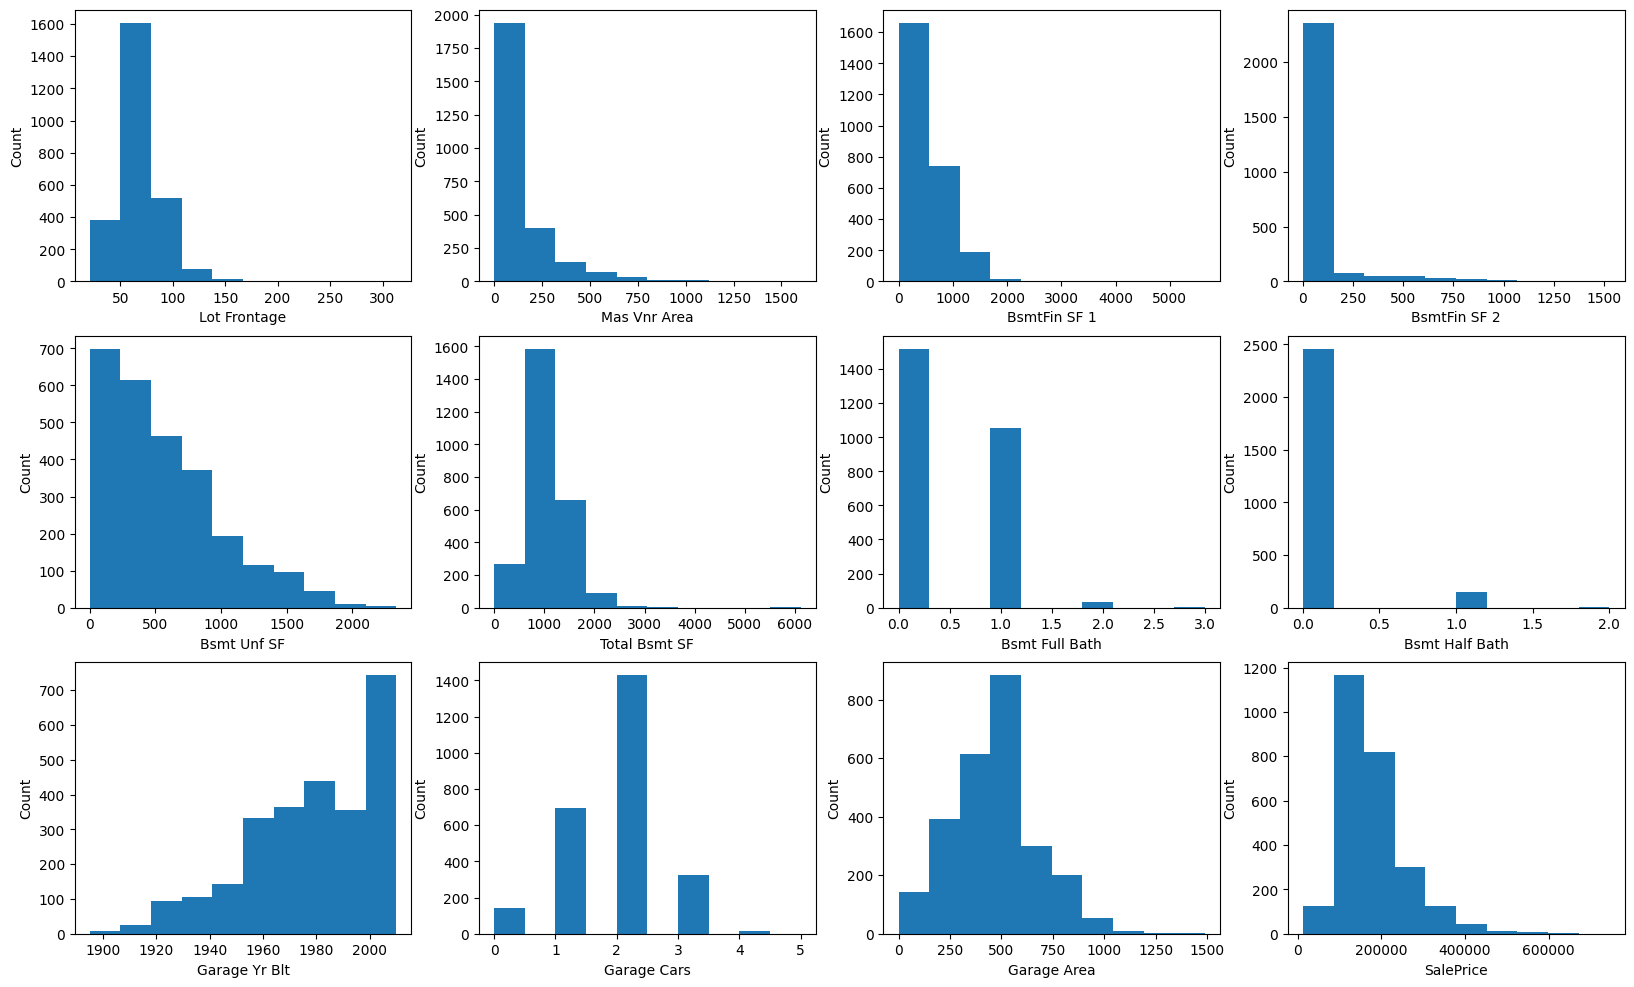

In [300]:
# Let's plot mpg and all of our predictors
subplots_per_row = 4
total_subplots = len(df.columns)
row_count = total_subplots // subplots_per_row
fig, subplots = plt.subplots(row_count,subplots_per_row, figsize = (20,4*row_count)) # Creating 2x4 subplots because we have 8 columns in our data
column_names = df.columns

subplots = subplots.flatten()[:len(column_names)]  # flatten and slice axs
for n, subplot in enumerate(subplots):             # Loop through axs
  subplot.hist(df[column_names[n]])
  subplot.set_xlabel(column_names[n])
  subplot.set_ylabel('Count')

### What do we notice?

- SalePrice and Lot Frontage are positively skewed
- All float features look positively skewed
- Some features appear categorical (only a few unique values per feature)
- Perhaps some outliers

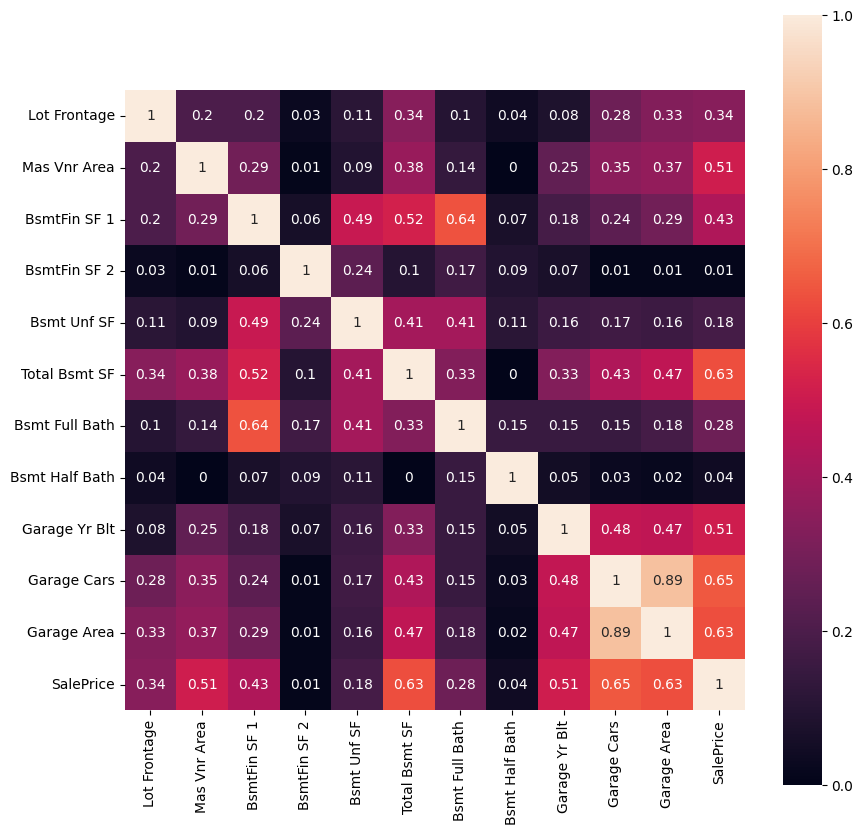

In [301]:
# Correlation plot — target and features
plt.figure(figsize=(10,10))
correlation_matrix = df.corr().abs().round(2)
sns.heatmap(data=correlation_matrix, annot=True, vmin=0, vmax=1, square=True) ;



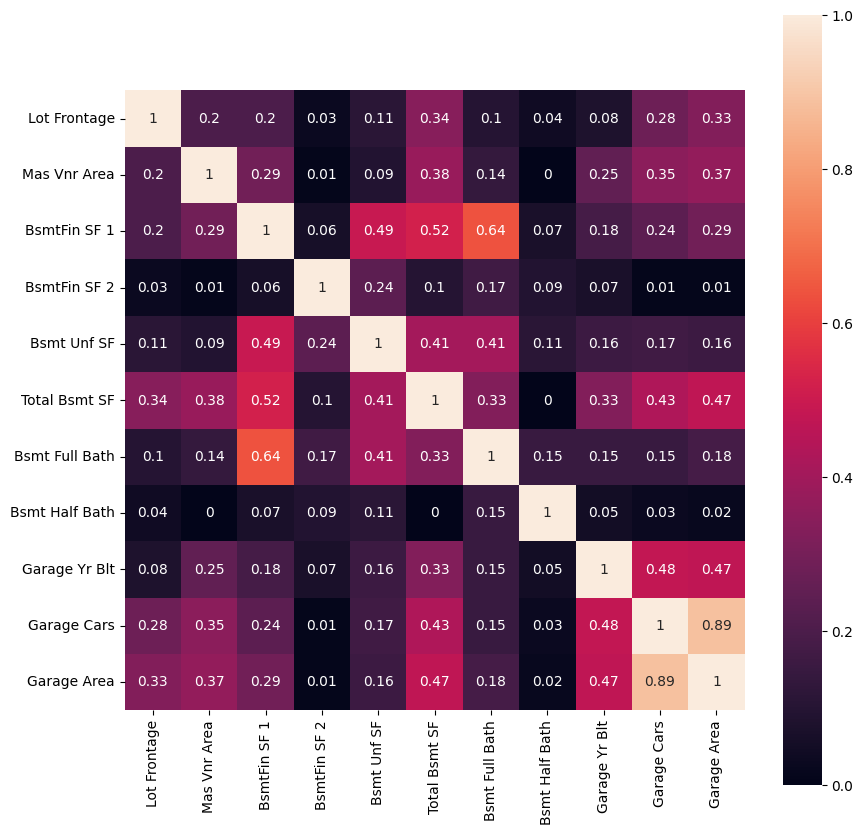

In [302]:
# Correlation plot — features only
plt.figure(figsize=(10,10))
correlation_matrix = df.drop( columns = [target_col] ).corr().abs().round(2)
sns.heatmap(data=correlation_matrix, annot=True, vmin=0, vmax=1, square=True) ;



In [303]:
correlation_matrix = df.corr().round(2)
correlation_matrix[target_col].abs().sort_values(ascending=False)

,SalePrice
SalePrice,1.00
Garage Cars,0.65
Garage Area,0.63
Total Bsmt SF,0.63
Garage Yr Blt,0.51
Mas Vnr Area,0.51
BsmtFin SF 1,0.43
Lot Frontage,0.34
Bsmt Full Bath,0.28
Bsmt Unf SF,0.18


<Axes: >

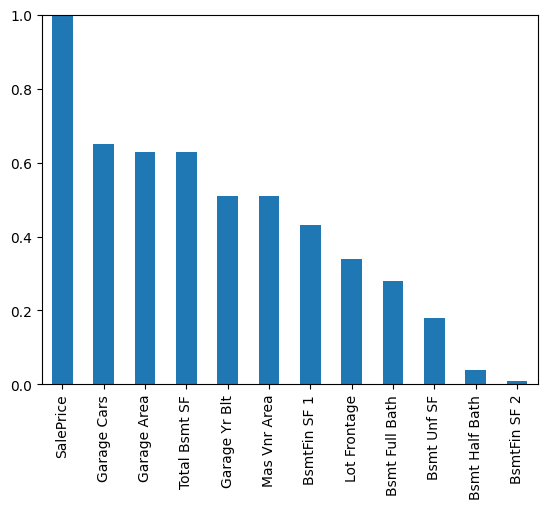

In [304]:
correlation_matrix = df.corr().round(2)
correlation_matrix[target_col].abs().sort_values(ascending=False).plot( kind="bar", ylim = [0,1])

In [305]:
corrs = df.corr().round(2).unstack().abs()
corrs.reset_index()

,level_0,level_1,0
0,Lot Frontage,Lot Frontage,1.00
1,Lot Frontage,Mas Vnr Area,0.20
2,Lot Frontage,BsmtFin SF 1,0.20
3,Lot Frontage,BsmtFin SF 2,0.03
4,Lot Frontage,Bsmt Unf SF,0.11
...,...,...,...
139,SalePrice,Bsmt Half Bath,0.04
140,SalePrice,Garage Yr Blt,0.51
141,SalePrice,Garage Cars,0.65
142,SalePrice,Garage Area,0.63


In [306]:
corrs = corrs[corrs < 1]
corrs.reset_index()

,level_0,level_1,0
0,Lot Frontage,Mas Vnr Area,0.20
1,Lot Frontage,BsmtFin SF 1,0.20
2,Lot Frontage,BsmtFin SF 2,0.03
3,Lot Frontage,Bsmt Unf SF,0.11
4,Lot Frontage,Total Bsmt SF,0.34
...,...,...,...
127,SalePrice,Bsmt Full Bath,0.28
128,SalePrice,Bsmt Half Bath,0.04
129,SalePrice,Garage Yr Blt,0.51
130,SalePrice,Garage Cars,0.65


In [307]:
corrs.sort_values(ascending = False).reset_index()

,level_0,level_1,0
0,Garage Area,Garage Cars,0.89
1,Garage Cars,Garage Area,0.89
2,Garage Cars,SalePrice,0.65
3,SalePrice,Garage Cars,0.65
4,BsmtFin SF 1,Bsmt Full Bath,0.64
...,...,...,...
127,Garage Cars,BsmtFin SF 2,0.01
128,Total Bsmt SF,Bsmt Half Bath,0.00
129,Mas Vnr Area,Bsmt Half Bath,0.00
130,Bsmt Half Bath,Mas Vnr Area,0.00


In [308]:
corrs.sort_values(ascending = False)[::2].reset_index()

,level_0,level_1,0
0,Garage Area,Garage Cars,0.89
1,Garage Cars,SalePrice,0.65
2,BsmtFin SF 1,Bsmt Full Bath,0.64
3,SalePrice,Garage Area,0.63
4,Garage Area,SalePrice,0.63
...,...,...,...
61,BsmtFin SF 2,Garage Area,0.01
62,Garage Area,BsmtFin SF 2,0.01
63,BsmtFin SF 2,Garage Cars,0.01
64,Total Bsmt SF,Bsmt Half Bath,0.00


### What do we notice?

- SalePrice vs. Lot Frontage do not appear to be highly correlated to each other
- BsmtFin SF 2 and Bsmt Half Bath are very independent from most other features, but also poorly coorelate with SalePrice
- Garage Area and Garage Cars coorelate with target well and each other fairly well, but don't correlate with other features nearly as much, meaning one of these could be a good candidate

In [309]:
df.size

31332

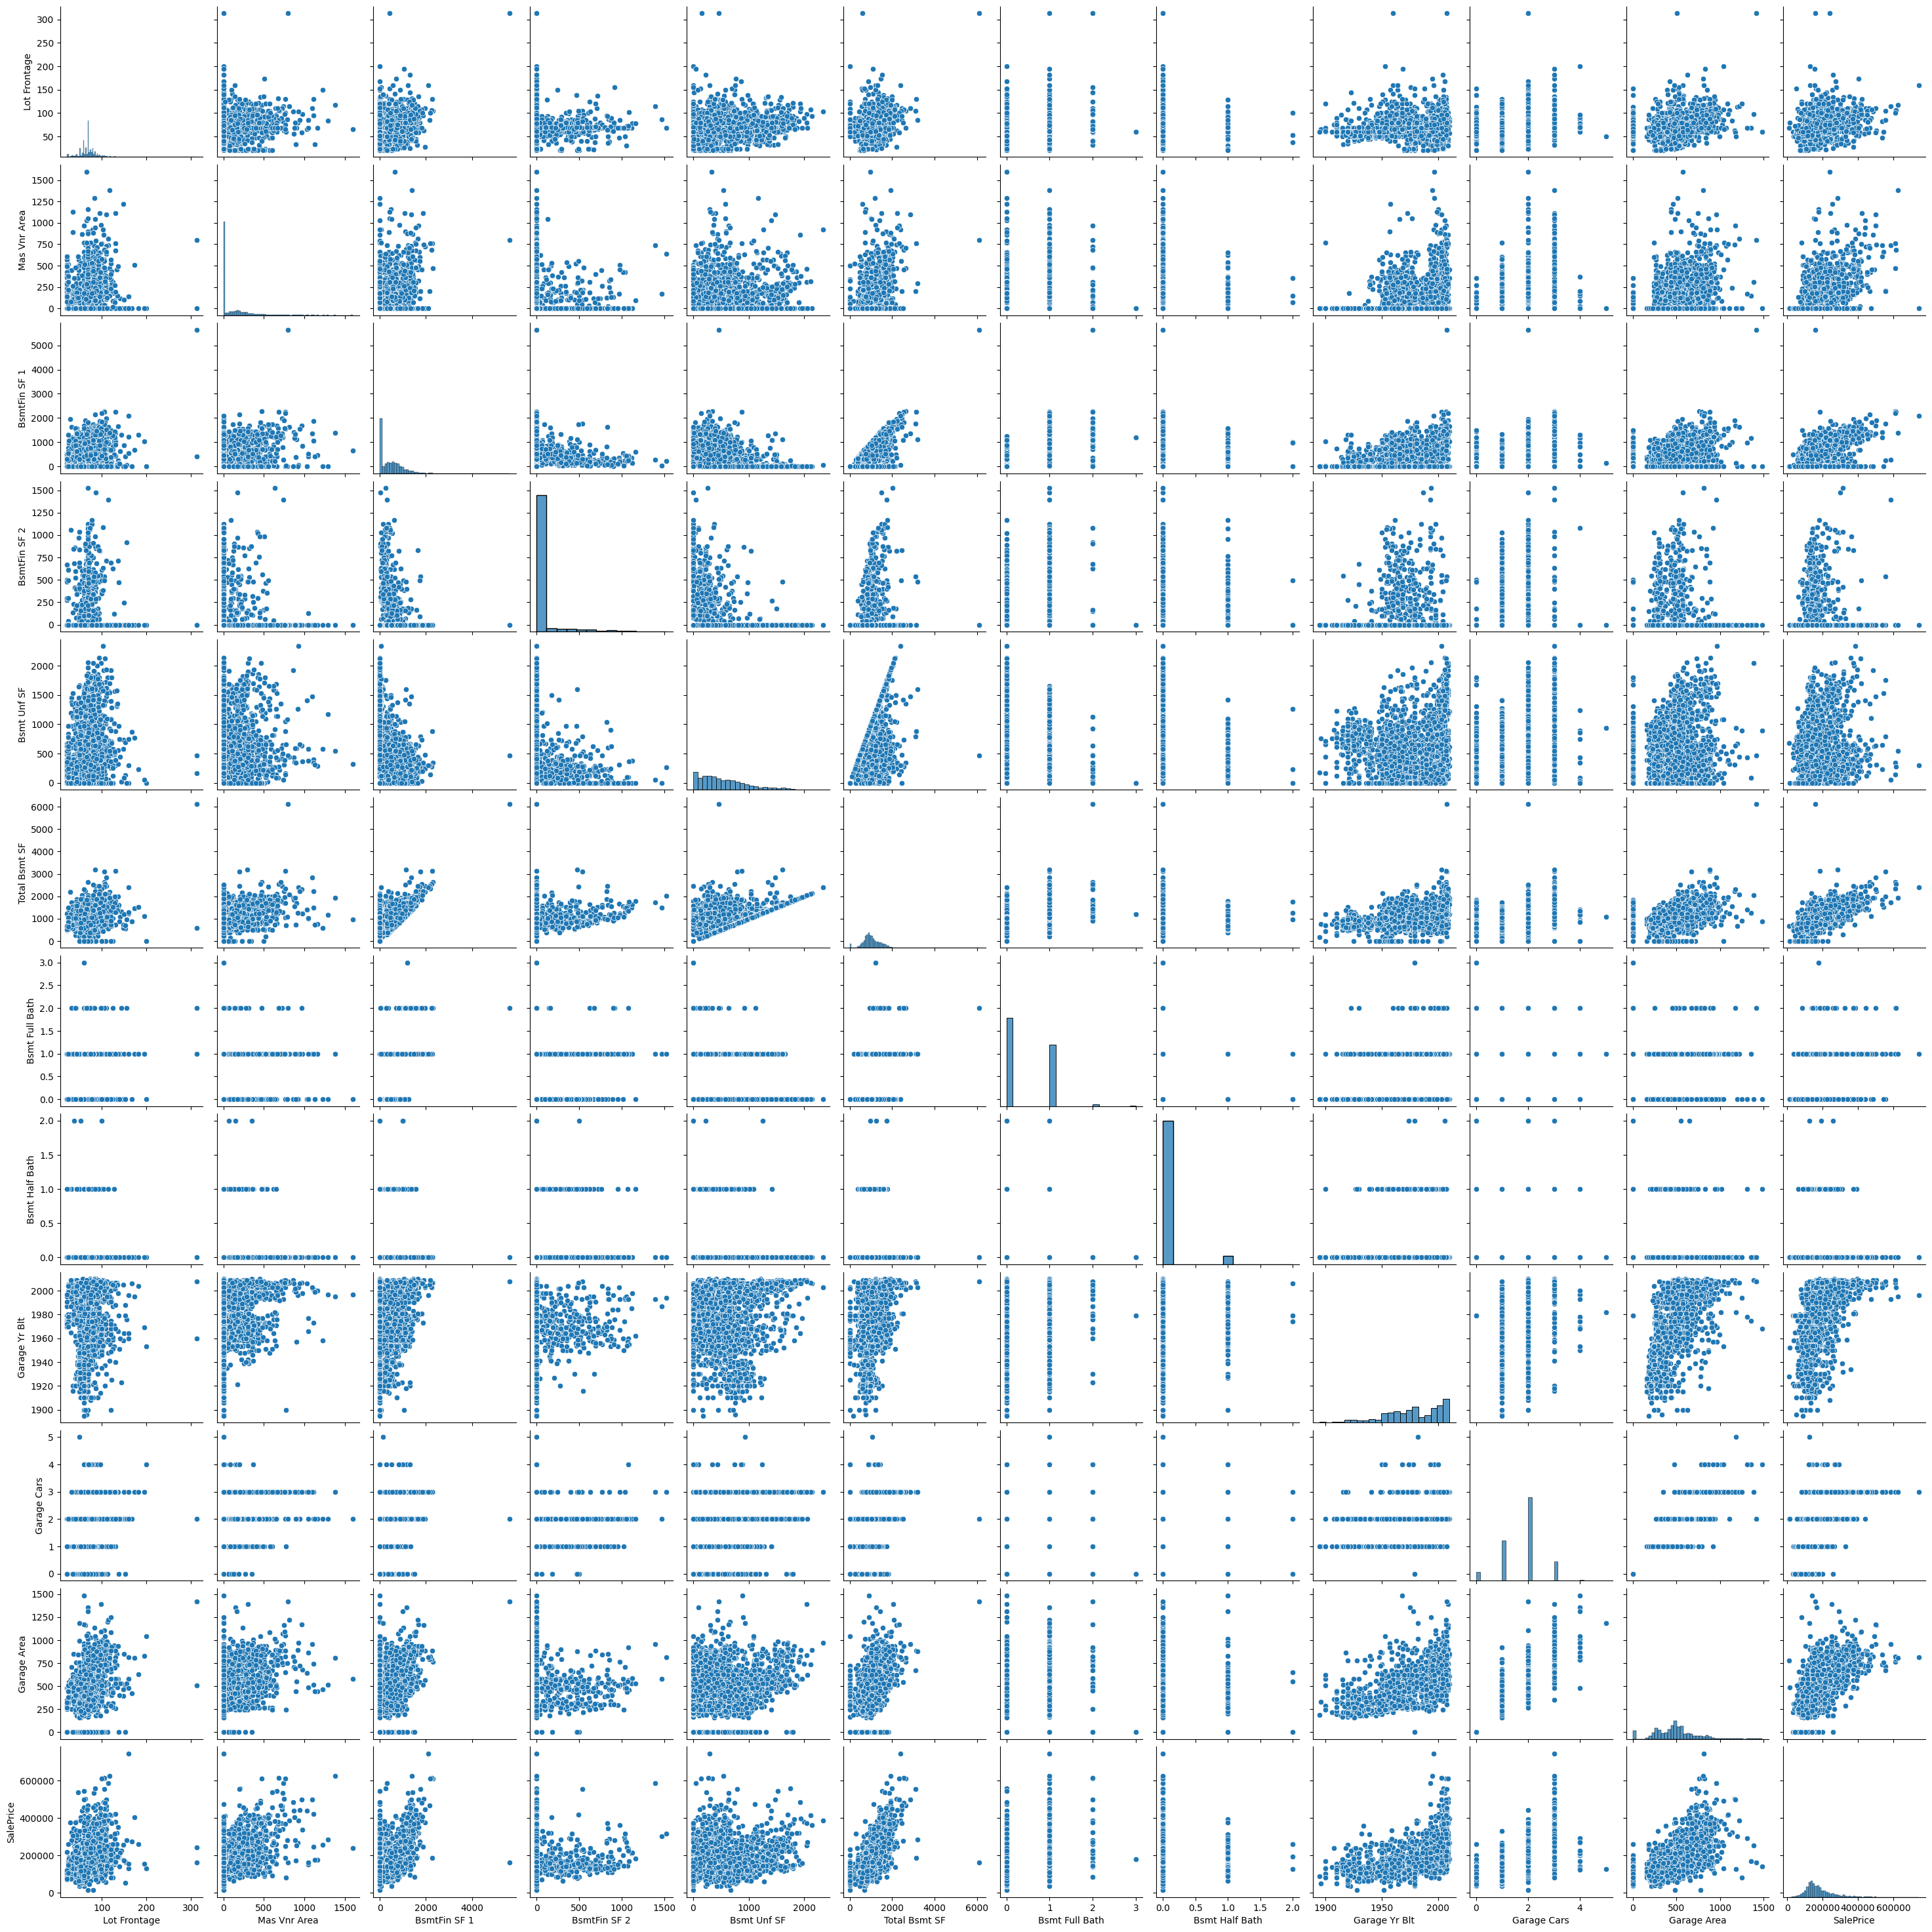

In [310]:
# Let's plot a pairplot
sns.pairplot(df) ;



### What do we notice?

- SalePrice vs. Lot Frontage is rather scattered, and does not appear to be linear.
- Many scattered relationships, some with some degree of potential linearity

## Processing



### Prepare data frame

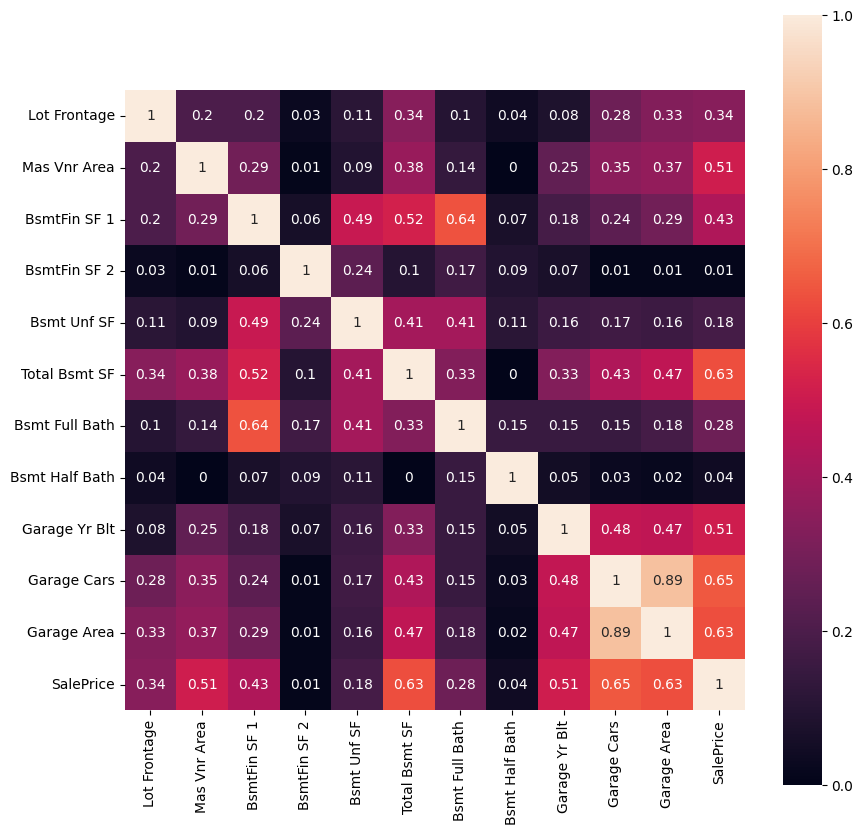

In [311]:
# Correlation plot — target and features (again)
plt.figure(figsize=(10,10))
correlation_matrix = df.corr().abs().round(2)
sns.heatmap(data=correlation_matrix, annot=True, vmin=0, vmax=1, square=True) ;



Linear Regression:

Here, we can make a few notes about the best features:
- BsmtFin SF 2 and Bsmt Half Bath are quite non-correlated with SalePrice (0.01 and 0.04, respectively), so we can safely exclude them
- Bsmt Unf SF, Bsmt Full Bath, and Lot Frontage are all weakly correlated (0.18, 0.28, and 0.34), but should be kept for now
- Garage Cars and Garage Area are strongly correlated with each other, so only one of these should be kept
- Everything else looks sufficiently independent that they may be kept

Ridge Regression & Lasso Regression:

- We allow the modeling process to help us decide which features to drop.

In [312]:
target_col = 'SalePrice'
feature_cols = list( df.drop( columns = [target_col] ) )
target_col, feature_cols

('SalePrice',
 ['Lot Frontage',
  'Mas Vnr Area',
  'BsmtFin SF 1',
  'BsmtFin SF 2',
  'Bsmt Unf SF',
  'Total Bsmt SF',
  'Bsmt Full Bath',
  'Bsmt Half Bath',
  'Garage Yr Blt',
  'Garage Cars',
  'Garage Area'])

In [314]:
# Split data frame into target and features
target   = df[target_col].copy()
features = df[feature_cols].copy()

In [315]:
# Verify features
features

,Lot Frontage,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Bsmt Full Bath,Bsmt Half Bath,Garage Yr Blt,Garage Cars,Garage Area
0,62.0,0.0,513.0,144.0,348.0,1005.0,1.0,0.0,1964.0,2.0,440.0
1,72.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1967.0,2.0,516.0
2,50.0,0.0,0.0,0.0,780.0,780.0,0.0,0.0,1979.0,1.0,544.0
3,68.0,0.0,484.0,0.0,491.0,975.0,1.0,0.0,2000.0,2.0,592.0
4,60.0,0.0,350.0,210.0,0.0,560.0,1.0,0.0,1971.0,2.0,576.0
...,...,...,...,...,...,...,...,...,...,...,...
2632,52.0,0.0,0.0,0.0,816.0,816.0,0.0,0.0,1985.0,2.0,528.0
2633,74.0,0.0,460.0,286.0,308.0,1054.0,1.0,0.0,1990.0,2.0,462.0
2634,61.0,0.0,960.0,0.0,266.0,1226.0,1.0,0.0,1981.0,2.0,484.0
2635,78.0,174.0,0.0,0.0,1064.0,1064.0,0.0,0.0,1974.0,2.0,478.0


In [316]:
# Verify target
target

,SalePrice
0,115400
1,90000
2,141000
3,254000
4,155000
...,...
2632,114500
2633,162000
2634,211500
2635,165000


In [317]:
type(features), features.shape, features.ndim

(pandas.core.frame.DataFrame, (2611, 11), 2)

In [318]:
type(target), target.shape, target.ndim

(pandas.core.series.Series, (2611,), 1)

### Fit & Assess Our Model

#### Ridge Regression — Sklearn

Now, we perform a ridge regression using sklearn:

In [320]:
# First, we scale the values with a scaler:
scaler = StandardScaler()
features_scaled = pd.DataFrame(scaler.fit_transform(features), columns=features.columns)

In [321]:
# Run a Single Split to test the model:
X_train, X_test, y_train, y_test = train_test_split(features_scaled, target, test_size = 0.2, random_state=42)

In [322]:
# Fit a ridge model using Sklearn
model = Ridge(alpha = 1)
model.fit(X_train, y_train)

( model.intercept_, model.coef_ )

(np.float64(178129.0914035436),
 array([ 5619.17393845, 15262.11838405, 11293.29222401,  2404.94794837,
         4631.52180349, 17490.47619638,  -178.41508893, -2049.02261323,
        16535.17810608, 22908.68351071,  1027.72919962]))

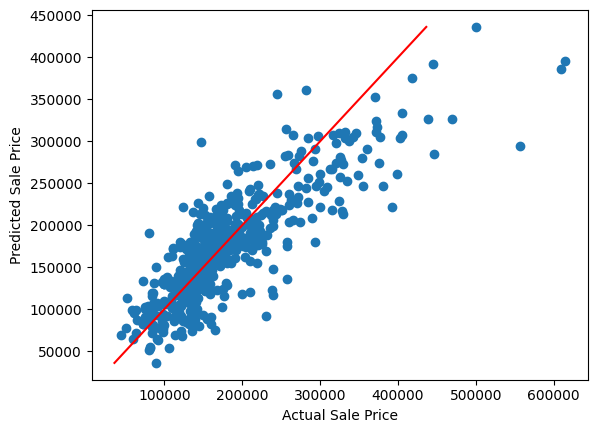

In [323]:
# See how well our model performs on our test data
y_pred = model.predict(X_test)
plt.scatter(y_test, y_pred)
plt.plot([min(y_pred), max(y_pred)],[min(y_pred), max(y_pred)], c='red')
plt.xlabel('Actual Sale Price')
plt.ylabel('Predicted Sale Price') ;

In [324]:
list(zip(y_test,y_pred))[:10]

[(109000, np.float64(133325.59544297104)),
 (112000, np.float64(103973.04067244881)),
 (193879, np.float64(201898.51893058285)),
 (266000, np.float64(273683.9046235869)),
 (376162, np.float64(273890.6194998873)),
 (223500, np.float64(186239.85265876647)),
 (270000, np.float64(226472.87038295408)),
 (137000, np.float64(139387.3371235864)),
 (392000, np.float64(221274.94439017933)),
 (137500, np.float64(189752.46266275537))]

We'll use RMSE as our performance metric.

In [325]:
# Calculate RMSE
y_pred = model.predict(X_test)
rmse = np.sqrt(np.mean(np.square(y_test - y_pred)))
print(f"RMSE: {rmse}")

RMSE: 46267.54729731008


In [326]:
# Check root mean squared error on test data
rmse = metrics.mean_squared_error(y_test, y_pred)**0.5
print(f"RMSE: {rmse}")

RMSE: 46267.54729731008


Perform the Regression:

In [327]:
# Specify values of alpha we want to try
alpha = [1e-15, 1e-10, 1e-8, 1e-4, 1e-3, 1e-2, 1e-1, 1, 2, 3, 4, 5, 10, 20, 30, 50]

# Create empty list to hold results
results_alpha = []

for a in alpha:
  # Train the model
  my_fit_rr = Ridge(alpha = a) # Looping through alpha
  my_fit_rr.fit(X_train, y_train)

  # Calculate CV RMSE
  results = cross_val_score(
      my_fit_rr,
      features_scaled,
      target,
      scoring='neg_root_mean_squared_error',
      cv = 10
      )
  rmse = abs(results.mean())
  results_alpha.append(rmse)

results_df = pd.DataFrame({'Alpha': alpha, 'RMSE': results_alpha})
print(results_df.sort_values(by=['RMSE']))

/usr/local/lib/python3.13/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=4.87337e-17): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/python3.13/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=1.24135e-17): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/python3.13/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=8.42875e-17): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/python3.13/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=6.18997e-17): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/python3.13/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=3.82655e-17): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/pytho

           Alpha          RMSE
15  5.000000e+01  46670.070080
14  3.000000e+01  46673.582977
13  2.000000e+01  46676.833205
12  1.000000e+01  46681.328981
11  5.000000e+00  46684.118014
10  4.000000e+00  46684.723477
9   3.000000e+00  46685.345525
8   2.000000e+00  46685.984470
7   1.000000e+00  46686.640633
6   1.000000e-01  46687.246173
5   1.000000e-02  46687.307518
4   1.000000e-03  46687.313660
3   1.000000e-04  46687.314275
2   1.000000e-08  46687.314343
1   1.000000e-10  46687.314343
0   1.000000e-15  46687.314343


In [328]:
results_df.sort_values( by = ["Alpha"])

,Alpha,RMSE
0,1.000000e-15,46687.314343
1,1.000000e-10,46687.314343
2,1.000000e-08,46687.314343
3,1.000000e-04,46687.314275
4,1.000000e-03,46687.313660
5,1.000000e-02,46687.307518
6,1.000000e-01,46687.246173
7,1.000000e+00,46686.640633
8,2.000000e+00,46685.984470
9,3.000000e+00,46685.345525


<Axes: >

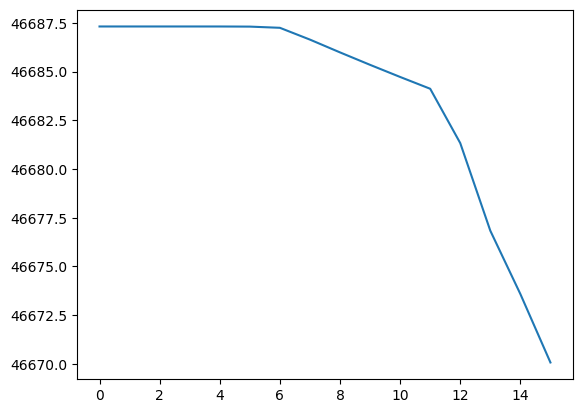

In [329]:
results_df.sort_values( by = ["Alpha"])["RMSE"].plot()

In [330]:
# Retrain the model w/ alpha = 20
my_fit_rr = Ridge(alpha = 20)
my_fit_rr.fit(X_train, y_train)

# Calculate CV RMSE
results = cross_val_score(my_fit_rr, features_scaled, target, scoring='neg_root_mean_squared_error', cv = 10)
rmse = abs(results.mean())
print(f"CV RMSE: {rmse}")

CV RMSE: 46676.83320543337


## Data Visualization/Communication of Results


### Residual Analysis

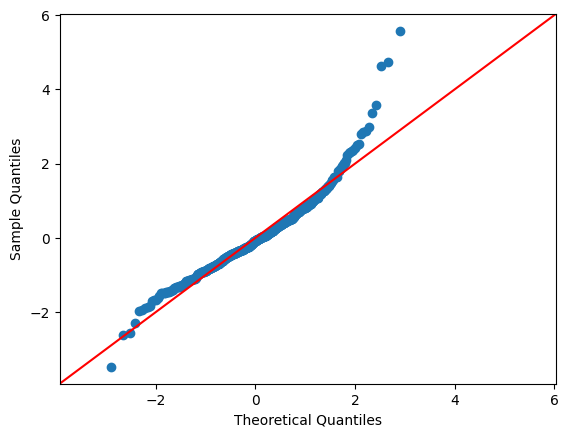

In [331]:
# QQ Plot - Residuals are normally distributed
res = y_test - y_pred
sm.qqplot(res, fit=True, line="45") ;

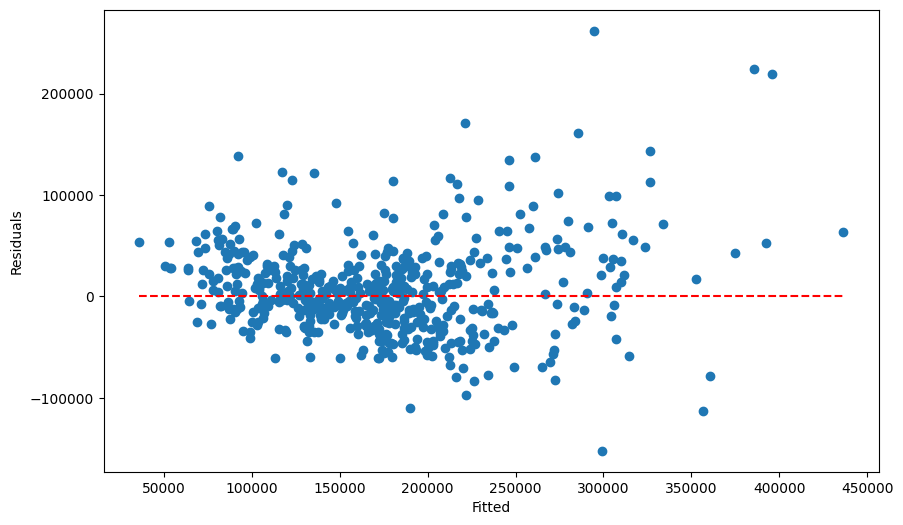

In [332]:
# Residuals vs Fitted (Predicted) Values - Constant variance
plt.figure(figsize = (10,6))
plt.scatter(y_pred, res)
plt.xlabel("Fitted")
plt.ylabel("Residuals")
plt.hlines(0, min(y_pred), max(y_pred), colors = 'red', linestyles = 'dashed') ;

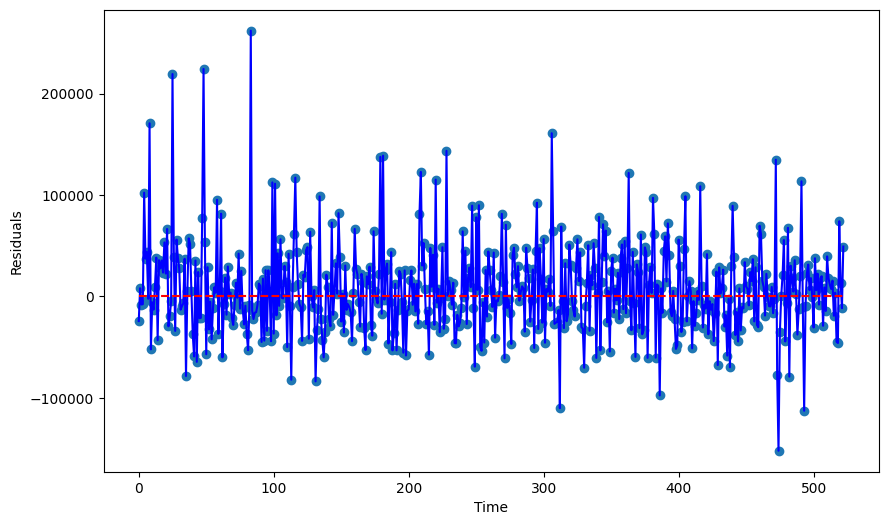

In [333]:
# Residuals vs Time - indepedence
plt.figure(figsize = (10,6))
plt.scatter(range(len(res)), res)
plt.plot(range(len(res)), res, 'b')
plt.xlabel("Time")
plt.ylabel("Residuals")
plt.hlines(0, min(range(len(res))), max(range(len(res))), colors = 'red', linestyles = 'dashed') ;

This result tells us that altogether, using multiple float features produces a better model for house sale price, better than using Garage Area on its own. However, the residual analysis still shows a non-normal distribution in the residuals, showing that something is awry in the fit between the data and the model, implying linear regression may not be properly modeling the relationship between the features and the target.

## Data Visualization/Communication of Results
